# IS 327 - Homework 2

Everything you need to complete is marked by "TODO" (both coding and written questions).

There are 20 of them. Make sure you attempt each of them. You get at least 60% of the grade even if your code is still buggy.

## Dataset: Predict Students's status

Dataset: https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

You can read about what each column is about on the same page.

Download this dataset and unzip it.

Place "data.csv" in the same directory as your jupyter notebook.

However, this is not the best practice since you need a better directory organization strategy. Ask GPT for the best practice for setting up a machine learning project. You will benefit from the knowledge in your final project. 

In [2]:
import pandas as pd
df = pd.read_csv("data.csv", sep=";")
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 1. Data exploration

In this section, you need to explore the dataset first. (5 pt)

1. Which column should be our label if we will build an ML classifier to predict students' outcomes? The answer can be found below. 

**TODO 1** (5 pt)

Answer: The "Target" variable that determines if a student will or will not drop out.

2. Select five columns (i.e., features) and explain why they can or cannot predict students' status. You are free to choose features (5 pt)

**TODO 2** (5 pt)

Answer: 

**Admission Grade** - Past behavior in terms of academic success could be an predictor of future success. However, some students behave differently in high school versus college.

**Previous qualification** - Similar to above, past performance in academic aptitude could be transferable to future success, thereby a reduced risk in dropping out. We have to be careful not to overemphasize past performance since it may not account for many of the changes college may bring about (i.e. environment, social behavior, etc).

**Tuition fees up to date** - Paying on time can indicate a student is on top of their duties and have a commitment to their education. A limitation to the efficacy of this variable is that there can be external factors that prevent students from paying that have nothing to do with their dedication to their studies. 

**Age at enrollment** - An age of a student could be an indication of materity, life responsibilities, and potential risks. This is a bit too crude of a metric though since it could interact with other factors such as socioeconomic background, parental status, etc that could negatively impact the model. 

**Course** - A particular set of courses or degree paths can be more rigorous or have a higher rate of drop outs. This could be a good predictor of success, barring any personal struggles a student might be having independently of academics.

In [3]:
# remove the enrolled class
df = df[df['Target'] != 'Enrolled']

# create the whole dataset (X, y)
X = df.drop('Target', axis=1)
y = df['Target']

n_samples = X.shape[0]
print('number of samples:', n_samples)
print('input feature size:', X.shape)
print('output data size:', y.shape)

number of samples: 3630
input feature size: (3630, 36)
output data size: (3630,)


**TODO 3** (5 pt)

How many students are "Graduate" and how many are "Dropout?" Use the cell below to code. However, you can use other means (e.g., Excel) to get the answer. 

Answer: 

In [5]:
# code here (not required)
graduate_count = len(df[df['Target']=='Graduate'])
dropout_count = len(df[df['Target'] == 'Dropout'])

print("Number of Graduates:", graduate_count)
print("Number of Dropouts:", dropout_count)

Number of Graduates: 2209
Number of Dropouts: 1421


In [6]:
# Train test split. From now on, you should distinguish the train and test datasets. 

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 2. Information gain

In this section, you will practice computing entropy and information gain. 


**TODO 4** (5 pt)

Write a code snippet to compute the entropy of the sample without any knowledge of the features. What is the initial entropy (only reserve four digits, e.g., 0.XXXX)? Hint: You will need the math module and use math.log2()

Answer: 

In [8]:
# code here
import math
total_samples = len(df)
p_grad = graduate_count/total_samples
p_drop = dropout_count/total_samples

entropy = - (p_grad *math.log2(p_grad) + p_drop*math.log2(p_drop))
print(f"Initial Entropy: {entropy:.4f}")

Initial Entropy: 0.9657


Use "Admission grade" to split the train set. This is a numerical variable. We first plot a violin plot to examine the relationship between admission grades and outcomes ("Graduate" versus "Dropout").

ATTENTION: You should **ONLY** use the train dataset to avoid introducing knowledge from the test dataset
You will need to remerge the X_train and y_train. But we prepared the code for you. This data frame (df_vis) will also be used to compute entropy. 

<Axes: xlabel='Admission grade', ylabel='Target'>

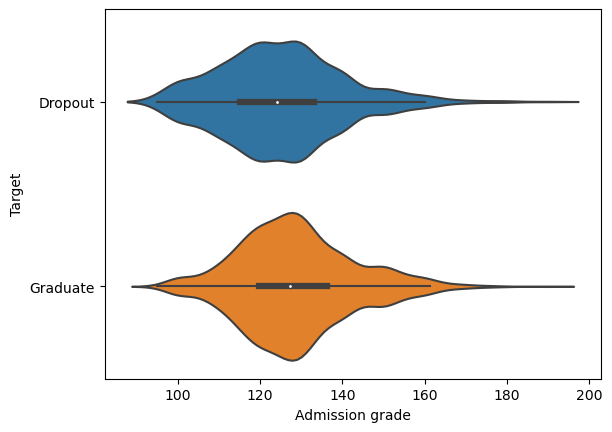

In [9]:
df_vis = pd.concat([X_train['Admission grade'], y_train], axis=1)

from seaborn import violinplot
violinplot(data=df_vis, x=df_vis['Admission grade'], y=df_vis['Target'])

**TODO 5** (5 pt)

Do you see where you should place your decision boundary from the violin plot? Choose a number. You will NOT be graded by the number you choose. However, you need to state your reason why you place the decision boundary at "Addmission grade" = XXX

Answer: I would place the decision boundary at Admission Grade = 120 since the regions below that admission grade are much thicker than above it, indicating a greater amount of dropouts/graduations. However, I originally attempted to ue 135 but the entropy only went down .1 or so. This number has reduced the entropy by the most significant amount.


**TODO 6** (5 pt)

Now compute the entropy based on this threshold. It is a bit more difficult, so we prepared the script for you. However, you should try to understand the code. Report the new entropy, reserving only four digits (i.e., 0.XXXX).

Answer: 


In [42]:
# supply your decision boundary here 
db = 120

In [43]:
# run this cell to compute new entropy
branch_1 = df_vis[df_vis['Admission grade'] >= db]
branch_2 = df_vis[df_vis['Admission grade'] < db]

In [44]:
p_1_1 = len(branch_1[branch_1['Target'] == 'Graduate'])/len(branch_1) 
p_1_2 = len(branch_1[branch_1['Target'] == 'Dropout'])/len(branch_1) 
p_2_1 = len(branch_2[branch_2['Target'] == 'Graduate'])/len(branch_2)
p_2_2 = len(branch_2[branch_2['Target'] == 'Dropout'])/len(branch_2)

w_1 = len(branch_1)/len(df_vis)
w_2 = len(branch_2)/len(df_vis)

In [45]:
# script for computing the new entropy
import math

entropy_2 = (w_1 * (p_1_1 * math.log2(p_1_1) + p_1_2 * math.log2(p_1_2))) * (-1) + \
 + (w_2 * (p_2_1 * math.log2(p_2_1) + p_2_2 * math.log2(p_2_2))) * (-1)
print(f"New Entropy: {entropy_2:.4f}")


New Entropy: 0.9585


**TODO 7** (5 pt)

What is your information gain? Use the cell below to show us how you computed it. Don't worry if your entropy increased and you get a negative information gain. If you are interested, tune the decision boundary to see whether you can get some information gain.

Answer: 


In [46]:
# code here
info_gain = entropy - entropy_2
print(f"Information Gain: {info_gain:.4f}")

Information Gain: 0.0072


## 3. Building a simple decision tree

In this section, you are tasked with building a simple decision tree classifier *without hyperparameter tuning and feature selection.*

https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier

Attention: From now on, you should use X_train, y_train, X_test, and y_test in your code

Use scikit learn's DecisionTreeClassifier to build a decision tree. 

Set max_depth to 3 for this exercise. max_depth will be a hyperparameter that you need to ajust in the future, but not now for the simple decision tree. 


In [ ]:
# **TODO 8** (5 pt)
# code here
# you may change the criterion to entropy because the default is gini purity
# however, this is not required. Just let you know. 
# set max_depth to 3
# set a random_state




**TODO 9** (5 pt)
Use sklearn's functionality to discover what the decision nodes are.
You can use export_text or plot_tree

export_text (more dependable): https://scikit-learn.org/stable/modules/generated/sklearn.tree.export_text.html

plot_tree: https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html

In [53]:
# code here
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import export_text

clf = DecisionTreeClassifier(max_depth=3, criterion='entropy', random_state=42)
clf.fit(X_train, y_train)

tree_rules = export_text(clf, feature_names=X_train.columns.tolist())
print(tree_rules)


|--- Curricular units 2nd sem (approved) <= 3.50
|   |--- Curricular units 2nd sem (enrolled) <= 0.50
|   |   |--- Tuition fees up to date <= 0.50
|   |   |   |--- class: Dropout
|   |   |--- Tuition fees up to date >  0.50
|   |   |   |--- class: Graduate
|   |--- Curricular units 2nd sem (enrolled) >  0.50
|   |   |--- Curricular units 2nd sem (approved) <= 2.50
|   |   |   |--- class: Dropout
|   |   |--- Curricular units 2nd sem (approved) >  2.50
|   |   |   |--- class: Dropout
|--- Curricular units 2nd sem (approved) >  3.50
|   |--- Tuition fees up to date <= 0.50
|   |   |--- Curricular units 2nd sem (approved) <= 5.50
|   |   |   |--- class: Dropout
|   |   |--- Curricular units 2nd sem (approved) >  5.50
|   |   |   |--- class: Dropout
|   |--- Tuition fees up to date >  0.50
|   |   |--- Curricular units 2nd sem (approved) <= 5.50
|   |   |   |--- class: Graduate
|   |   |--- Curricular units 2nd sem (approved) >  5.50
|   |   |   |--- class: Graduate



**TODO 10** (5 pt)

Examine the decision tree. If the classifier is aimed at finding at-risk students and preventing them from dropping out, is it useful? Why?

Answer: This is not the most useful. We need to figure out the best max_depth value since having none decreases interpretability greatly, and having it set to something like 3 fails to capture the complexity of the classification. Either way, it does not seem to be predicting things accurately just yet. 

### Evaluate the simple classifier you just build
Use your test dataset to evaluate the performance of your simple decision tree classifer

You can use the basic accuracy score: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html

You are also welcome to try other metrics

In [54]:
# TODO 11 (5 pt)
# evaluate your classifier use the test dataset
# code here
from sklearn.metrics import accuracy_score

y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Test Accuracy: {:.4f}".format(accuracy))


Test Accuracy: 0.8857


## 4. Build a more thoughtful decision tree

You have built a simple decision tree. However, you may notice that this decision tree has problems. Also, it is not built thoughtfully, meaning that we did not do hyperparameter tuning and feature selection. In this section, you will try to build a more thoughtful decision tree.

Select 10 features from the 36 features of the dataset that:

1. Related to students' risk of dropping out
2. Not a consequence of student's dropping out (e.g., stop paying for tuition)

**TODO 12** (5 pt) 

This one is a bit redundant since it is similar to TODO 2, but I would encourage you to keep TODO 2 as it was and think about how your understanding has changed. After all, you are not graded by what features you chose)

List 10 features you select and explain why you selected them.

Answer: 

Admission grade: Indicates the student's academic preparedness at the time of admission.

Previous qualification (grade): Reflects historical academic performance, suggesting the level of prior achievement.

Tuition fees up to date: Serves as a proxy for financial stability and commitment to studies.

Age at enrollment: Provides insight into maturity and potential external responsibilities that might impact academic focus.

Curricular units 1st sem (approved):Measures early academic success, which is a strong indicator of future performance.

Curricular units 1st sem (grade): Offers a quantitative view of performance in the initial academic period.

Scholarship holder: May indicate financial need as well as the support structures available to the student.

Father's occupation: Acts as a socio-economic indicator, which can correlate with the resources available to the student.

Mother's qualification: Often linked to the academic environment at home and overall family support.

Application mode: Captures nuances in the admission process (e.g., regular vs. special programs) that might influence preparedness and subsequent dropout risk.

In [57]:
# Sample Code
# You can use the sample code below judiciously to keep only the 10 features you select.
# However, do not limit yourself to the features listed below.
# I commented them out. To use the code, you need to uncomment them.




'''feature_names = ['Course',
     'Previous qualification (grade)',
     'Admission grade',
     'Tuition fees up to date',
     'Age at enrollment',
     'Curricular units 1st sem (enrolled)',
     'Curricular units 1st sem (evaluations)',
     'Curricular units 1st sem (approved)',
     'Curricular units 1st sem (grade)',
     'Curricular units 2nd sem (enrolled)',
     'Curricular units 2nd sem (evaluations)',
     'Curricular units 2nd sem (approved)',
     'Curricular units 2nd sem (grade)'] '''


"feature_names = ['Course',\n     'Previous qualification (grade)',\n     'Admission grade',\n     'Tuition fees up to date',\n     'Age at enrollment',\n     'Curricular units 1st sem (enrolled)',\n     'Curricular units 1st sem (evaluations)',\n     'Curricular units 1st sem (approved)',\n     'Curricular units 1st sem (grade)',\n     'Curricular units 2nd sem (enrolled)',\n     'Curricular units 2nd sem (evaluations)',\n     'Curricular units 2nd sem (approved)',\n     'Curricular units 2nd sem (grade)'] "

In [56]:
# TODO 13 (5 pt)
# create your new train and test dataset with the 10 features you select
# to make the code below run, your data should be X, and your label should be y
# code here

feature_names = [
    'Admission grade',
    'Previous qualification (grade)',
    'Tuition fees up to date',
    'Age at enrollment',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Scholarship holder',
    "Father's occupation",
    "Mother's qualification",
    'Application mode'
]

X = df[feature_names]
y = df['Target']

print("Selected features:")
print(X.head())

Selected features:
   Admission grade  Previous qualification (grade)  Tuition fees up to date  \
0            127.3                           122.0                        1   
1            142.5                           160.0                        0   
2            124.8                           122.0                        0   
3            119.6                           122.0                        1   
4            141.5                           100.0                        1   

   Age at enrollment  Curricular units 1st sem (approved)  \
0                 20                                    0   
1                 19                                    6   
2                 19                                    0   
3                 20                                    6   
4                 45                                    5   

   Curricular units 1st sem (grade)  Scholarship holder  Father's occupation  \
0                          0.000000                   0    

In [58]:
# Train test split 
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [60]:
# TODO 14 (5 pt)
# Now use your X_train, y_train to build a decision tree classifer
# Use cross validation to figure out the best parameter max_depth: limiting it to 10 but you can try different intervals
# For example, you can try [3, 6, 9] or [2,4,6,8,10]
# I suggest use GridSearchCV from sklearn 
# since the code will be the easiest to read
# there is a sample script on Canvas under the week 6 module
# You should be able to print your best max_depth
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# 1. Define a parameter grid for max_depth
#    You can adjust the list of depths as needed
param_grid = {
    'max_depth': [3, 4, 5, 6, 7, 8, 9, 10]  
}

# 2. Create a DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42)

# 3. Set up GridSearchCV to find the best max_depth
grid_search = GridSearchCV(
    estimator=dt, 
    param_grid=param_grid, 
    scoring='accuracy',    # or another metric if you prefer
    cv=5,                  # 5-fold cross-validation
    n_jobs=-1              # use all cores if available
)

# 4. Fit the grid search on the training data
grid_search.fit(X_train, y_train)

# 5. Print out the best parameter and the corresponding cross-validation score
print("Best parameters found:", grid_search.best_params_)
print("Best cross-validation accuracy: {:.4f}".format(grid_search.best_score_))


Best parameters found: {'max_depth': 3}
Best cross-validation accuracy: 0.8592


**TODO 15** (5 pt)

Use plot_tree or export_text to examine the decision tree you just build with the best max_depth. What is the first feature used to make decision? Does it suprise you that this is the first feature? Why or why not?

Answer: This isn't entirely surprising because early academic success is theoretically a great predictor of a student's ability to continue and ultimately successfully graduate. This aligns with why the model would priortize this metric for making its predictions of student outcomes.


In [61]:
from sklearn.tree import export_text

best_clf = grid_search.best_estimator_

tree_rules = export_text(best_clf, feature_names=feature_names)
print(tree_rules)


|--- Curricular units 1st sem (approved) <= 4.50
|   |--- Curricular units 1st sem (approved) <= 3.50
|   |   |--- Application mode <= 3.00
|   |   |   |--- class: Dropout
|   |   |--- Application mode >  3.00
|   |   |   |--- class: Dropout
|   |--- Curricular units 1st sem (approved) >  3.50
|   |   |--- Tuition fees up to date <= 0.50
|   |   |   |--- class: Dropout
|   |   |--- Tuition fees up to date >  0.50
|   |   |   |--- class: Graduate
|--- Curricular units 1st sem (approved) >  4.50
|   |--- Tuition fees up to date <= 0.50
|   |   |--- Curricular units 1st sem (grade) <= 13.33
|   |   |   |--- class: Dropout
|   |   |--- Curricular units 1st sem (grade) >  13.33
|   |   |   |--- class: Graduate
|   |--- Tuition fees up to date >  0.50
|   |   |--- Curricular units 1st sem (grade) <= 12.21
|   |   |   |--- class: Graduate
|   |   |--- Curricular units 1st sem (grade) >  12.21
|   |   |   |--- class: Graduate



In [63]:
# TODO 16 (5 pt)
# Evaluate your "thoughtful" decision tree with the best max_depth using the test dataset
# You can use the basic accuracy score: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html
# You are also welcome to try other metrics
# code here
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

thoughtful_clf = grid_search.best_estimator_

y_pred_thoughtful = thoughtful_clf.predict(X_test)


accuracy_thoughtful = accuracy_score(y_test, y_pred_thoughtful)
print("Test Accuracy: {:.4f}".format(accuracy_thoughtful))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_thoughtful))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_thoughtful))



Test Accuracy: 0.8471

Confusion Matrix:
[[192  85]
 [ 26 423]]

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.88      0.69      0.78       277
    Graduate       0.83      0.94      0.88       449

    accuracy                           0.85       726
   macro avg       0.86      0.82      0.83       726
weighted avg       0.85      0.85      0.84       726



**TODO 17** (5 pt)

Did your thoughtful decision tree get a better score (e.g., accuracy) than your simple decision tree? If it is worse, can you give ONE reason why we should still use the thoughtful decision tree? If not, answer why you think the thoughtful decision tree gets better scores.

Answer: The thoughtful decision tree did receive a slightly lower accuracy score. However, using the thoughtful decision tree is still the better model since using more carefully selected metrics improves interpretability, which can be important in making actionable deciions even if the accuracy itself is still slightly lower. 



**TODO 18** (5 pt)
Challenge you self by adding one more hyperparameter to max_depth. 

Some candidate hyperparameters can be found here: https://www.geeksforgeeks.org/how-to-tune-a-decision-tree-in-hyperparameter-tuning/

Use GridSearchCV this time since the code will be the most readable.


In [64]:
# code here
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [3, 4, 5, 6, 7, 8, 9, 10],
    'min_samples_split': [2, 4, 6, 8, 10]
}


dt = DecisionTreeClassifier(random_state=42)


grid_search_2 = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)


grid_search_2.fit(X_train, y_train)


print("Best parameters found:", grid_search_2.best_params_)
print("Best cross-validation accuracy: {:.4f}".format(grid_search_2.best_score_))

Best parameters found: {'max_depth': 3, 'min_samples_split': 2}
Best cross-validation accuracy: 0.8592


In [65]:
# TODO 19 (5 pt)
# Evaluate your new, hopefully more thoughtful decision tree
# You can use the basic accuracy score: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html
# You are also welcome to try other metrics
# code here
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Use the best estimator from the second grid search
final_clf = grid_search_2.best_estimator_

# Predict outcomes on the test dataset
y_pred_final = final_clf.predict(X_test)

# Compute the accuracy score
accuracy_final = accuracy_score(y_test, y_pred_final)
print("Final model accuracy: {:.4f}".format(accuracy_final))

# Display additional evaluation metrics
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))



Final model accuracy: 0.8471

Confusion Matrix:
[[192  85]
 [ 26 423]]

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.88      0.69      0.78       277
    Graduate       0.83      0.94      0.88       449

    accuracy                           0.85       726
   macro avg       0.86      0.82      0.83       726
weighted avg       0.85      0.85      0.84       726



**TODO 20** (5 pt)

Explore literature and news articles about machine learning applied to education. What did you find? How do you now view the decision tree classifers you build to predict students' outcomes?

Answer: Machine learning is being used more and more to predict student outcomes. Decision trees may be less accurate than more complex models, they have a great deal of interpretability, which can help educators understand to some degree which factors could have the greatest impact on students who may drop out. Using models with a great deal of explainability creates a level of transparency that makes the models useful for creating strategies to help at risk students. 

## 5. Conclusion

Congratulations! You've reached the end. I hope you have built more confidence in machine learning and started to appreciate its complexity beyond the coding part. This is why this class is about concepts rather than programming. In real life, you will have to make many decisions when building a machine-learning model!

## Reference

Cite the link to any material (e.g., tutorial, code) you use for this assignment.

Referenes: I only used the tutorial code that was linked in this assignment



## Generative AI usage declarations

Declare here whether and how you used generative AI for this homework.

Declaration: I used it for todo 12 to streamline variable selection, and to verify/modify code. 


